In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
features = pd.read_csv("selected_features.csv", index_col=0)
species = pd.read_csv("output/final_data/merged_all_species.csv", index_col=0)[["decimalLatitude", "decimalLongitude", "species"]]
species_all = pd.merge(species, features, on=["decimalLatitude", "decimalLongitude"], how="right")
print(species_all.shape)
print(species_all.columns.to_list())

(30759, 21)
['decimalLatitude', 'decimalLongitude', 'species', 'gbifID', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI', 'SAVI', 'BSI', 'Silicates', 'Carbonates', 'Iron_Oxides', 'Slope', 'Snow_Duration_Pct', 'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'true_present']


In [3]:
climatic_cols = species_all.columns[4:-1]
print(climatic_cols)
print(species_all[climatic_cols].shape)

Index(['wc2.1_30s_bio_10', 'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect',
       'Curvature', 'EVI', 'SAVI', 'BSI', 'Silicates', 'Carbonates',
       'Iron_Oxides', 'Slope', 'Snow_Duration_Pct', 'Topo_Solar_Radiation_MJ',
       'TRI', 'TWI'],
      dtype='str')
(30759, 16)


In [4]:
#print(species_all.species.value_counts())
# odrzucam te poniżej 500 obserwacji
mask = species_all["species"].value_counts() > 500
species_all = species_all[species_all["species"].isin(mask[mask].index)]
print(species_all.species.value_counts())

species
Linaria alpina           4304
Carex myosuroides        1647
Carex parviflora         1636
Armeria alpina           1445
Sibbaldia procumbens     1387
Petrocallis pyrenaica    1049
Astragalus alpinus        878
Comastoma tenellum        773
Erigeron alpinus          733
Juncus triglumis          656
Carex rupestris           634
Draba dubia               591
Kalmia procumbens         588
Name: count, dtype: int64


In [5]:
# losowe punkty
background = pd.read_csv("../output/features/pseudo_absence.csv")
background.head()

,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,...,Slope,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,true_present
0,pseudo_2,13.697968,46.325520,16.500000,23.966074,570,448,-6.3,-0.450000,224.0,...,22.0,0.0,255.0,1327.0,54.0,250.0,0.891549,0.250,7.493905,0
1,pseudo_3,8.516397,46.279167,12.183333,24.661802,373,204,-5.9,-1.933333,85.0,...,39.0,0.0,191.0,907.0,53.0,463.0,0.577664,1.500,7.402440,0
2,pseudo_4,14.482414,47.542547,12.933333,31.827656,453,212,-7.9,-3.600000,227.0,...,26.0,0.0,277.0,1192.0,51.0,293.0,0.871590,0.625,7.834172,0
3,pseudo_5,7.162609,44.614140,11.000000,18.697920,229,296,-6.8,10.783334,214.0,...,24.0,36.0,207.0,1090.0,55.0,378.0,0.991181,3.375,8.516088,0
4,pseudo_6,8.102843,45.908615,12.049999,24.043575,244,158,-6.2,-2.150000,328.0,...,46.0,77.0,209.0,1254.0,56.0,427.0,0.716958,0.500,7.468302,0


In [6]:
# łaczmy duplikaty do jednego rekordu (gbifID różne gbifID, ale te same współrzędne i gatunek)
print(species_all.shape)
species_all.drop_duplicates(subset=["decimalLongitude", "decimalLatitude", "species"], inplace=True)
print(species_all.shape)

(16321, 21)
(10687, 21)


In [7]:
# to jest raczej niemożliwe, ale sprawdźmy z ciekawości czy losowe punkty też się powtórzyły
print(background.shape)
background.drop_duplicates(subset=["decimalLongitude", "decimalLatitude"], inplace=True)
print(background.shape)

(11983, 24)
(11983, 24)


In [8]:
species_all.drop(columns=["gbifID", "true_present"], inplace=True)
background.drop(columns=["gbifID", "true_present"], inplace=True)
background["species"] = "background"

In [9]:
background.columns

Index(['decimalLongitude', 'decimalLatitude', 'wc2.1_30s_bio_10',
       'wc2.1_30s_bio_15', 'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19',
       'wc2.1_30s_bio_6', 'wc2.1_30s_bio_9', 'Aspect', 'Curvature', 'EVI',
       'SAVI', 'BSI', 'Slope', 'Snow_Duration_Pct', 'Soil_Clay',
       'Soil_Organic_Carbon', 'Soil_pH', 'Soil_Sand',
       'Topo_Solar_Radiation_MJ', 'TRI', 'TWI', 'species'],
      dtype='str')

In [10]:
# wyrzucanie z background rekordów, które są bardzo blisko rekordów z gatunkami (np. w promieniu 500 m)
from sklearn.neighbors import BallTree
tree = BallTree(np.radians(species_all[["decimalLatitude", "decimalLongitude"]]), metric="haversine")
# zapytanie o najbliższego sąsiada
distances, indices = tree.query(np.radians(background[["decimalLatitude", "decimalLongitude"]]), k=1)
# odległość w metrach (Ziemia ma promień około 6371 km)
distances_m = distances.flatten() * 6371 * 1000
# filtrujemy rekordy, które są dalej niż 50 m od najbliższego rekordu z gatunkiem
background = background[distances_m > 50]
print(background.shape)

(11977, 23)


# absencje

## pierwsze podejście
```
Założenie:
	organizmy nie wchodzą ze sobą w interakcje ekologiczne.
	tzn. wystąpienie jednego gatunku nie wpływa na obecność drugiego.

	Obserwator zapisuje każdy gatunek, który napotka, nie jest wybredny.

Implikacje:
	Jeżeli w obszarze $x$ obserwujemy wystąpienie gatunku $A$, to mamy pewność, że był tam obserwator.
	Jeżeli w tym samym obszarze $x$ nie obserwujemy wystąpienia $B$ to mamy "pewność", że go tam nie ma. Możemy przypisać '0'.
```

Text(0.5, 0, 'Liczba obserwacji w klastrze')

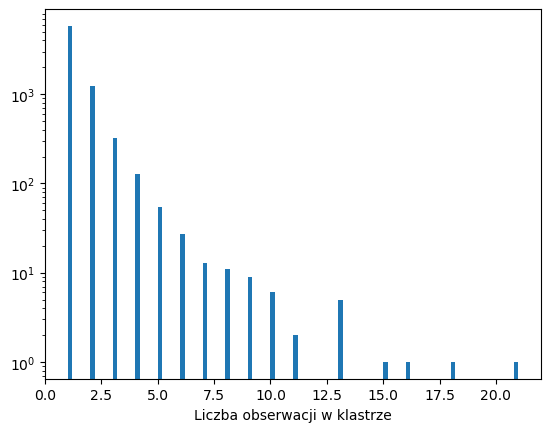

In [11]:
# klastrujemy obserwacje w obszary obserwacji, po współrzędnych geograficznych
# dbscan

from sklearn.cluster import DBSCAN
eps = 0.05/6371.0 # 50m w radianach (chyba)
dbscan = DBSCAN(eps=eps, min_samples=1,  metric='haversine') # metryka do danych geograficznych
# min_samples = 1, nie chcemy odrzucać samotnych punktów
clusters = dbscan.fit_predict(np.radians(species_all[["decimalLatitude", "decimalLongitude"]]))
tags, counts = np.unique(clusters, return_counts=True)
plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Liczba obserwacji w klastrze")

In [12]:
print(tags.shape)
print(species_all.shape)

(7642,)
(10687, 19)


In [13]:
species_all["cluster"] = clusters
cluster_pd = pd.DataFrame({"cluster": tags, "count": counts})

cluster_pd.head()

,cluster,count
0,0,2
1,1,1
2,2,1
3,3,1
4,4,1


In [14]:
species_all = species_all.merge(cluster_pd, on="cluster", how="inner")
species_all[species_all.cluster == 3]

,decimalLatitude,decimalLongitude,species,wc2.1_30s_bio_10,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,EVI,SAVI,...,Silicates,Carbonates,Iron_Oxides,Slope,Snow_Duration_Pct,Topo_Solar_Radiation_MJ,TRI,TWI,cluster,count
4,47.27309,13.753556,Armeria alpina,5.366667,-11.9,-8.116667,62.0,8.62512,0.448664,0.157538,...,0.094555,0.009146,0.004259,8.0,67.0,0.681731,3.125,9.656257,3,1


In [15]:
# sprawdzmy czy miejsca obserwacji się powtarzają
species_all[species_all[["decimalLongitude", "decimalLatitude"]].duplicated(keep=False)].sort_values(by=["decimalLongitude", "decimalLatitude"])

,decimalLatitude,decimalLongitude,species,wc2.1_30s_bio_10,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,EVI,SAVI,...,Silicates,Carbonates,Iron_Oxides,Slope,Snow_Duration_Pct,Topo_Solar_Radiation_MJ,TRI,TWI,cluster,count
852,44.845190,5.392760,Armeria alpina,13.633333,-4.5,13.633333,204.0,8.112714,1.158276,0.482934,...,0.092571,-0.017851,0.023019,21.0,7.0,1.020323,1.875,8.271811,577,2
853,44.845190,5.392760,Carex rupestris,13.633333,-4.5,13.633333,204.0,8.112714,1.158276,0.482934,...,0.092571,-0.017851,0.023019,21.0,7.0,1.020323,1.875,8.271811,577,2
1058,44.829310,5.477040,Armeria alpina,13.100000,-5.2,13.100000,0.0,1.300135,1.428577,0.815521,...,0.133083,0.059834,-0.004290,2.0,29.0,0.862994,0.125,10.499577,701,2
1059,44.829310,5.477040,Erigeron alpinus,13.100000,-5.2,13.100000,0.0,1.300135,1.428577,0.815521,...,0.133083,0.059834,-0.004290,2.0,29.0,0.862994,0.125,10.499577,701,2
1259,44.789540,5.510190,Armeria alpina,12.683333,-5.7,12.683333,263.0,10.577443,1.834930,0.860253,...,0.092897,0.045831,-0.005414,15.0,33.0,0.963954,0.500,8.717655,818,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3254,47.487222,13.647778,Linaria alpina,4.983333,-11.7,-8.033333,292.0,3.756717,0.856660,0.268936,...,0.070617,-0.064657,0.022343,14.0,72.0,0.763253,0.750,9.138828,2014,2
0,47.661111,14.264722,Armeria alpina,8.783334,-9.0,-5.050000,43.0,7.186920,1.608008,0.922302,...,0.119468,0.105713,-0.008937,14.0,61.0,0.633023,3.125,8.937199,0,2
1,47.661111,14.264722,Carex parviflora,8.783334,-9.0,-5.050000,43.0,7.186920,1.608008,0.922302,...,0.119468,0.105713,-0.008937,14.0,61.0,0.633023,3.125,8.937199,0,2
196,46.506394,14.766247,Armeria alpina,9.083333,-9.2,-5.050000,316.0,3.049699,1.822586,0.499795,...,0.076443,0.103751,-0.005685,36.0,77.0,0.734094,1.000,7.878571,176,3


In [16]:
# do cluster_pd dodajemy kolumny dla każdego gatunku, z informacją o tym czy występuje w danym klastrze (binarne)
binarne = pd.crosstab(species_all["cluster"], species_all["species"]).clip(upper=1)
cluster_pd = cluster_pd.merge(binarne, on="cluster")
cluster_pd.head()

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Carex rupestris,Comastoma tenellum,Draba dubia,Erigeron alpinus,Juncus triglumis,Kalmia procumbens,Linaria alpina,Petrocallis pyrenaica,Sibbaldia procumbens
0,0,2,1,0,0,1,0,0,0,0,0,0,0,0,0
1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0
2,2,1,1,0,0,0,0,0,0,0,0,0,0,0,0
3,3,1,1,0,0,0,0,0,0,0,0,0,0,0,0
4,4,1,1,0,0,0,0,0,0,0,0,0,0,0,0


In [17]:
species_all[species_all["cluster"] == 0]

,decimalLatitude,decimalLongitude,species,wc2.1_30s_bio_10,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,EVI,SAVI,...,Silicates,Carbonates,Iron_Oxides,Slope,Snow_Duration_Pct,Topo_Solar_Radiation_MJ,TRI,TWI,cluster,count
0,47.661111,14.264722,Armeria alpina,8.783334,-9.0,-5.05,43.0,7.18692,1.608008,0.922302,...,0.119468,0.105713,-0.008937,14.0,61.0,0.633023,3.125,8.937199,0,2
1,47.661111,14.264722,Carex parviflora,8.783334,-9.0,-5.05,43.0,7.18692,1.608008,0.922302,...,0.119468,0.105713,-0.008937,14.0,61.0,0.633023,3.125,8.937199,0,2


<Axes: >

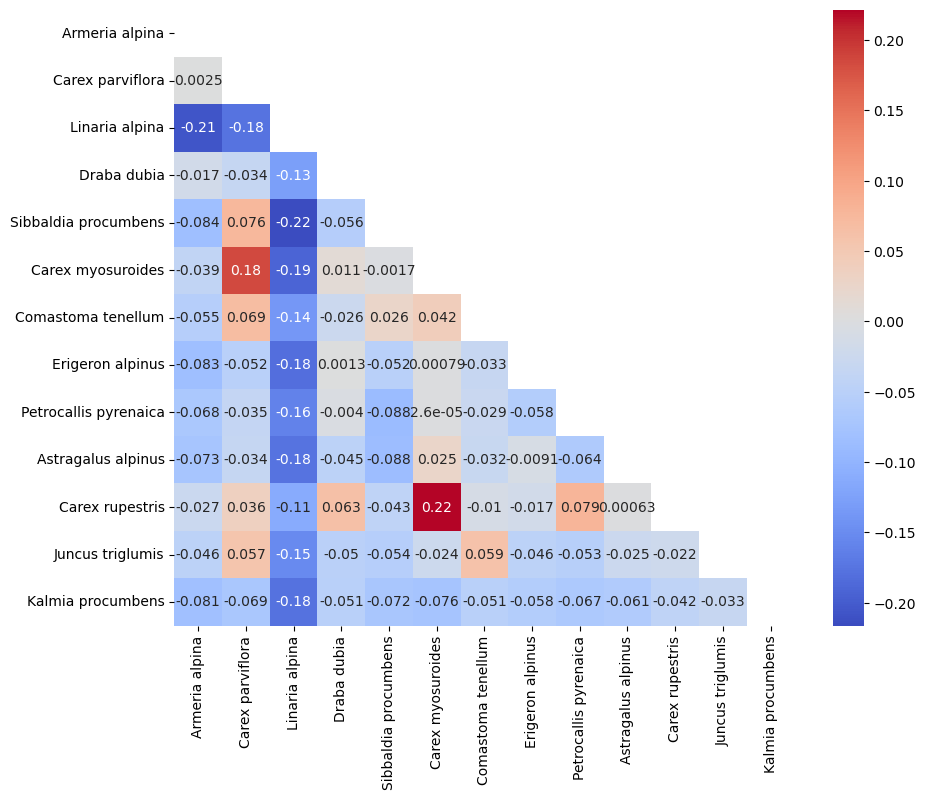

In [18]:
# sprawdzamy jak często gatunki występują razem w klastrach
cor_matrix = cluster_pd[species_all["species"].unique()].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(cluster_pd[species_all["species"].unique()].corr(), annot=True, cmap="coolwarm",
	mask=np.triu(cor_matrix))

Linaria alpina koreluje ujemnie z całą resztą. Najpewniej wynika to z tego, że mamy najwięcej rekordów dla niej, tzn. ma często jedynkę.
Korelacja pewnie nie jest najlepszą miarą. Dla większości par, dla większości rekordów mamy (0,0). Co "spłaszcza" nam wynik.

Zapamiętajmy narazie te korelacje, potem może je uwzględnimy.

Narazie zamiast tego spójrzmy na punktową informację wzajemną.

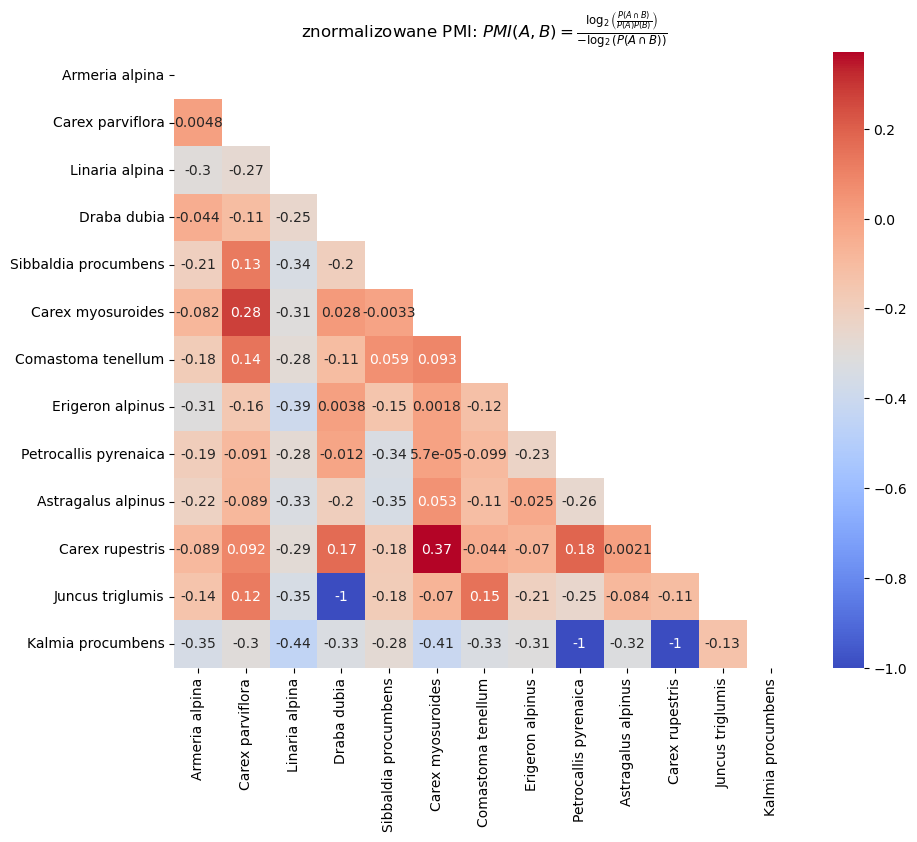

In [19]:
species_names = species_all["species"].unique()
tmp_matrix = np.zeros((len(species_names), len(species_names)))
for i, sp1 in enumerate(species_names):
	for j, sp2 in enumerate(species_names[:i+1]):
		AandB = ((cluster_pd[sp1] == 1) & (cluster_pd[sp2] == 1)).mean()
		A = (cluster_pd[sp1] == 1).mean()
		B = (cluster_pd[sp2] == 1).mean()
		# P(kolumna/wiersz)
		if A*B > 0 and AandB > 0:
			pmi = np.log2(AandB /(A*B))
			pmi /= -np.log2(AandB) # normalizacja
		else:
			pmi = -1
		tmp_matrix[i, j] = pmi
		tmp_matrix[j, i] = pmi

plt.figure(figsize=(10, 8))
sns.heatmap(tmp_matrix, annot=True, cmap="coolwarm", xticklabels=species_names,
			yticklabels=species_names, mask=np.triu(np.ones_like(tmp_matrix, dtype=bool)))
plt.title(r"znormalizowane PMI: $PMI(A,B) = \frac{\log_2\left(\frac{P(A \cap B)}{P(A)P(B)}\right)}{-\log_2(P(A \cap B))}$")
plt.show()

Podoba mi się bardziej, bo widać na przykład, że Petrocallis pyrenaica nigdy nie występuje w otoczeniu Kalmia procumbens.

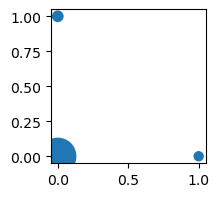

In [20]:
_, counts = np.unique(cluster_pd[["Kalmia procumbens", "Petrocallis pyrenaica"]].values, axis=0, return_counts=True)
plt.figure(figsize=(2, 2))
plt.scatter(_[:,0], _[:,1], s=counts*0.1)
plt.show()

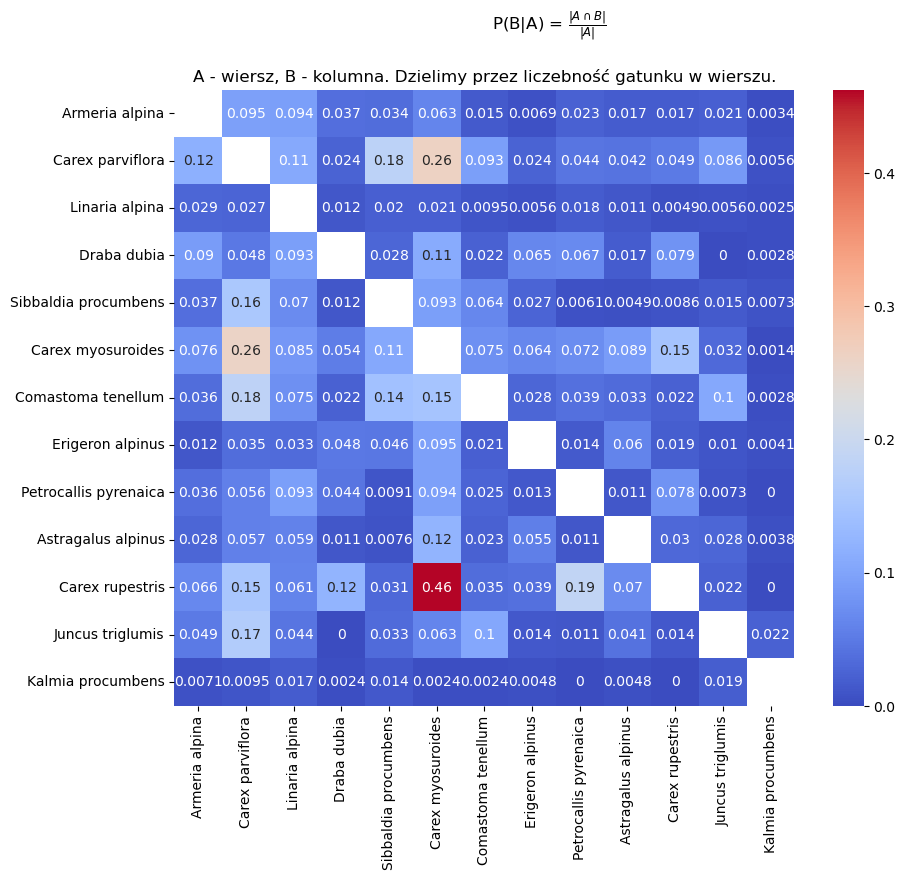

In [21]:
species_names = species_all["species"].unique()
tmp_matrix = np.zeros((len(species_names), len(species_names)))
for i, sp1 in enumerate(species_names):
	for j, sp2 in enumerate(species_names[:i+1]):
		AandB = ((cluster_pd[sp1] == 1) & (cluster_pd[sp2] == 1)).sum()
		A = (cluster_pd[sp1] == 1).sum()
		B = (cluster_pd[sp2] == 1).sum()
		# P(kolumna/wiersz)
		tmp_matrix[i, j] = AandB / A
		tmp_matrix[j, i] = AandB / B

plt.figure(figsize=(10, 8))
sns.heatmap(tmp_matrix, annot=True, cmap="coolwarm", xticklabels=species_names,
			yticklabels=species_names, mask=np.eye(tmp_matrix.shape[0], dtype=bool))
plt.suptitle(r"P(B|A) = $\frac{|A \cap B|}{|A|}$")
plt.title("A - wiersz, B - kolumna. Dzielimy przez liczebność gatunku w wierszu.")
plt.show()

Powyższe wykresy mówią nam raczej o współwystępowaniu, nie o biologicznych interakcjach. Warto dołożyć do tego jeszcze informacje o klastrowaniu się w domenie klimatycznej. Możliwe, że Kalmia i Petrocallis występują po prostu w różnego typu klimacie.

# Przewidujmy!

In [24]:
# dodajemy kolumny z wartswami bioklimatycznymi
# dla klastru będzie to średnia wartość bioklimatyczna dla wszystkich obserwacji w klastrze
# można wymyślić coś lepszego, np nie tylko średnia, ale też odchylenie itp, ale na razie zostawiamy tylko średnią
srednie = species_all.groupby("cluster")[climatic_cols].mean()
cluster_pd = cluster_pd.merge(srednie, on="cluster")

In [25]:
cluster_pd.head()

,cluster,count,Armeria alpina,Astragalus alpinus,Carex myosuroides,Carex parviflora,Carex rupestris,Comastoma tenellum,Draba dubia,Erigeron alpinus,...,SAVI,BSI,Silicates,Carbonates,Iron_Oxides,Slope,Snow_Duration_Pct,Topo_Solar_Radiation_MJ,TRI,TWI
0,0,2,1,0,0,1,0,0,0,0,...,0.922302,-0.043679,0.119468,0.105713,-0.008937,14.0,61.0,0.633023,3.125,8.937199
1,1,1,1,0,0,0,0,0,0,0,...,1.052070,-0.158483,0.117667,0.077254,-0.010071,24.0,59.0,0.928606,1.625,8.512902
2,2,1,1,0,0,0,0,0,0,0,...,0.113996,0.105939,0.106640,-0.022429,0.026383,24.0,93.0,0.882927,1.750,8.508546
3,3,1,1,0,0,0,0,0,0,0,...,0.157538,-0.019927,0.094555,0.009146,0.004259,8.0,67.0,0.681731,3.125,9.656257
4,4,1,1,0,0,0,0,0,0,0,...,1.261540,-0.342135,0.089882,0.165368,-0.009502,7.0,75.0,0.753672,2.625,9.542705


---
Tutaj trochę metryk

In [26]:
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_auc_score

def signal_per_species(y_true, proba, names):
	"""
	przyjmuje macierz y_truesignal_per_spe
	macierz proba z prawdopodobieństwami
	i listę nazw gatunków
	"""
	rows = []
	y_true = np.asarray(y_true)

	if isinstance(proba, list):
		P = np.full(y_true.shape, np.nan)
		for i, pr in enumerate(proba):
			if pr.shape[1] == 2:
				P[:, i] = pr[:, 1]
	else:
		P = np.asarray(proba)

	for i, sp in enumerate(names):
		m = ~np.isnan(P[:, i])
		yt, p = y_true[m, i], P[m, i]
		pos = int(yt.sum())
		base = yt.mean()
		ap = average_precision_score(yt, p)

		rows.append({
            "species": sp,
            "support": pos,
            "%1": base,
            "avg_prec": ap,
            "lift": (ap - base) / (1 - base) if base != 1 else np.nan,
            "roc_auc": roc_auc_score(yt, p)
        })
		signal = pd.DataFrame(rows).sort_values("lift", ascending=False)
        
	return signal


def map_scorer(estimator, X, y):
    """Średnie AP po gatunkach. 
	Potrzebne, bo przy scoring = "accuracy" dostaję ciągle error. Kiedy w foldzie nie ma jedynki.
    Obsługuje multi-output predict_proba (lista (n,2))."""
    
    proba = estimator.predict_proba(X)
    #if not isinstance(proba, list):           # na wypadek single-output
    #    proba = [proba]
    P = np.column_stack([
        p[:, 1] if p.shape[1] == 2 else np.zeros(p.shape[0])  # p(klasa=1); brak pozytywów w treningu -> 0
        for p in proba
    ])
    y = np.asarray(y)
    aps = [average_precision_score(y[:, i], P[:, i])
           for i in range(y.shape[1]) if y[:, i].sum() > 0]    # skip foldu bez 1 dla danego gatunku
    return float(np.mean(aps)) if aps else np.nan

from sklearn.base import clone

def oof_proba(estimator, X, y, splitter, groups=None):
    """Zwraca macierz prawdopodobieństw P (n, n_species) zebraną poza foldem treningowym.
    Każdy wiersz jest przewidziany dokładnie raz. Zmniejsza to problem niepełnego supportu."""
    n, k = y.shape
    P = np.full((n, k), np.nan)
    for tr, te in splitter.split(X, y, groups=groups):
        m = clone(estimator)
        m.fit(X[tr], y[tr])
        proba = m.predict_proba(X[te])
        if isinstance(proba, list):
            for i, pr in enumerate(proba):
                if pr.shape[1] == 2:
                    P[te, i] = pr[:, 1]
        else:
            P[te] = proba
    return P


## Model przewidujący $Y^N$

In [27]:
# najpierw jeden model, który przewiduje wektor

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.model_selection import KFold


param_dist = {
    "max_features":      uniform(0.2, 0.5),
    "min_samples_leaf":  randint(1, 12),
    "min_samples_split": randint(2, 20),
    "max_depth":         [None, 10, 16, 24, 32],
}

search = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1),
    param_distributions=param_dist,
    n_iter=10,
    n_jobs=-1,
    random_state=42,
	scoring=map_scorer,
    refit=True,
    verbose=1,
)

In [28]:
species_names = species_all["species"].unique().tolist()
X = cluster_pd.drop(columns=["cluster", "count"] + species_names).values
y = cluster_pd[species_names].values

# nie powinno być leaku, bo RandomizedSearchCV robi wewnętrzny split
search.fit(X, y)

print("best params:", search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params: {'max_depth': 16, 'max_features': np.float64(0.3912309956335814), 'min_samples_leaf': 4, 'min_samples_split': 4}


In [29]:
rf1 = search.best_estimator_
kf = KFold(n_splits=5, shuffle=True, random_state=42)
P_oof = oof_proba(rf1, X, y, splitter=kf) # też może zająć chwilę bo 5 razy fituje model do danych z różnych foldów
# pewnie dałoby się to napisać efektywniej, ale nie wiem czy korzystając z sklearn

In [30]:
signal1 = signal_per_species(y, P_oof, species_names)

print(signal1.to_string(index=False, float_format='%.3f'))
signal1.to_csv("signal1.csv", index=False)

              species  support    %1  avg_prec  lift  roc_auc
       Linaria alpina     2839 0.371     0.728 0.567    0.809
    Kalmia procumbens      420 0.055     0.580 0.556    0.957
       Armeria alpina      873 0.114     0.542 0.482    0.816
Petrocallis pyrenaica      551 0.072     0.444 0.400    0.874
 Sibbaldia procumbens      818 0.107     0.398 0.325    0.828
          Draba dubia      356 0.047     0.353 0.321    0.841
   Astragalus alpinus      527 0.069     0.310 0.259    0.840
    Carex myosuroides      721 0.094     0.279 0.204    0.808
     Juncus triglumis      367 0.048     0.237 0.199    0.861
     Carex parviflora      711 0.093     0.255 0.179    0.789
     Erigeron alpinus      483 0.063     0.210 0.156    0.772
      Carex rupestris      229 0.030     0.178 0.152    0.813
   Comastoma tenellum      362 0.047     0.139 0.096    0.770


Oceńmy wartość feature'ów.

Zgodnie z przykładami ze strony sklearn ([link do strony](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html)) atrybut 'feature_importances_ może być mylący dla featurów o "dużej kardynalności", czyli dużej liczbie unikatowych wartości. Nasze wartości teoretycznie nie powinny się powtarzać, ale zobaczmy sobie na liczby unikatowych wartości dla każdego feateuru, nawet dla kontekstu. Może być tak, że rozdzielczość jest na tyle niska, że dla jakiejś zmiennej mamy bardzo mało unikatów.

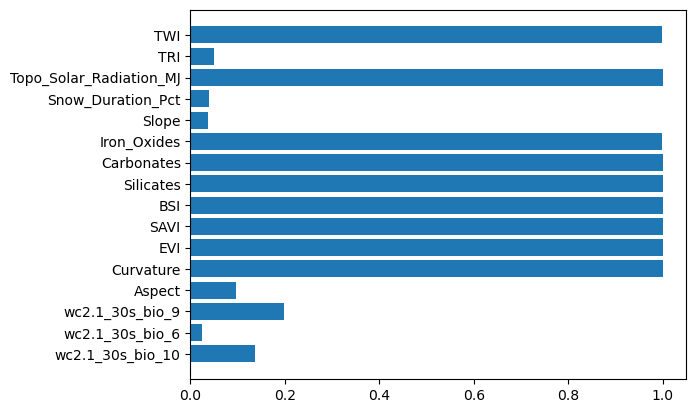

In [31]:
plt.barh(climatic_cols, cluster_pd[climatic_cols].nunique()/len(cluster_pd))
plt.show()

Widzimy, że dla wielu zmiennych, powyżej 50% rekordów ma unikatową wartość. Zastosuję się więc do zaleceń sklearn i użyję ważności cech opartej o permutację.

In [32]:
from sklearn.inspection import permutation_importance

imp_per_fold = []
for tr, te in kf.split(X, y):
    m = clone(rf1).fit(X[tr], y[tr])
    r = permutation_importance(
        m, X[te], y[te],
        scoring=map_scorer,
        n_repeats=30, random_state=42, n_jobs=-1,
    )
    imp_per_fold.append(r.importances_mean)

imp = np.vstack(imp_per_fold)
imp_mean = imp.mean(axis=0)
imp_std  = imp.std(axis=0) # zmienność między foldami

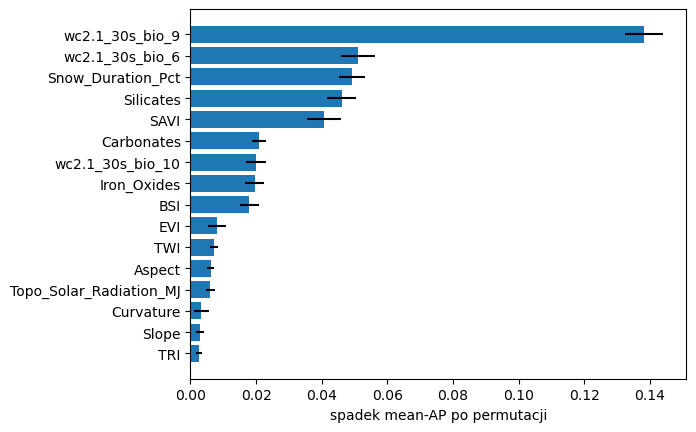

In [33]:
order = np.argsort(imp_mean)
plt.barh(np.array(climatic_cols)[order], imp_mean[order], xerr=imp_std[order])
plt.xlabel("spadek mean-AP po permutacji")
plt.show()

---
Powyższe wyniki są całkiem fajne, ale dodałbym lepszy split na train-test.

## Y^N + split blokami

In [34]:
from sklearn.model_selection import GroupKFold

# przypisujemy koordynaty geograficzne do klastrów
centroids = (species_all.groupby("cluster")[["decimalLongitude", "decimalLatitude"]]
                        .mean().rename(columns={"decimalLongitude": "lon",
                                                "decimalLatitude": "lat"}))

coords = cluster_pd.merge(centroids, on="cluster", how="left")[["lon", "lat"]].values

# grupujemy klastry w większe bloki, żeby zwiększyć szansę, że w train i test będą obserwacje z różnych miejsc
block_deg = 0.5
bx = np.floor(coords[:, 0] / block_deg).astype(int)
by = np.floor(coords[:, 1] / block_deg).astype(int)
blocks = bx * 100000 + by

X = cluster_pd.drop(columns = species_names + ["cluster", "count"]).values
y = cluster_pd[species_names].values

print(len(tags))
print(len(np.unique(blocks)))

7642
85


In [35]:
search_blocks = RandomizedSearchCV(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1),
    param_distributions=param_dist,
    n_iter=10,
    n_jobs=-1,
    random_state=42,
	scoring=map_scorer,
    refit=True,
    verbose=1,
    cv=GroupKFold(n_splits=5).split(X, y, groups=blocks)
)

In [36]:
# ten sam search co wcześniej
search_blocks.fit(X, y)

print("best params:", search_blocks.best_params_)
	
rf2 = search_blocks.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params: {'max_depth': 16, 'max_features': np.float64(0.21029224714790123), 'min_samples_leaf': 2, 'min_samples_split': 13}


In [37]:
gkf = GroupKFold(n_splits=5)
P_oof = oof_proba(rf2, X, y, splitter=gkf, groups=blocks)

signal_block = signal_per_species(y, P_oof, species_names)

print(signal_block.to_string(index=False, float_format='%.3f'))
signal_block.to_csv("signal_block.csv", index=False)

              species  support    %1  avg_prec  lift  roc_auc
       Linaria alpina     2839 0.371     0.673 0.480    0.762
    Kalmia procumbens      420 0.055     0.391 0.355    0.930
       Armeria alpina      873 0.114     0.315 0.226    0.649
   Astragalus alpinus      527 0.069     0.269 0.214    0.811
 Sibbaldia procumbens      818 0.107     0.274 0.186    0.789
Petrocallis pyrenaica      551 0.072     0.236 0.176    0.795
     Juncus triglumis      367 0.048     0.201 0.161    0.842
          Draba dubia      356 0.047     0.184 0.144    0.796
    Carex myosuroides      721 0.094     0.214 0.132    0.773
     Carex parviflora      711 0.093     0.205 0.123    0.760
     Erigeron alpinus      483 0.063     0.173 0.118    0.753
   Comastoma tenellum      362 0.047     0.085 0.039    0.721
      Carex rupestris      229 0.030     0.040 0.010    0.609


---

Sprawdźmy sobie jeszcze dla spermutowanego y.

In [38]:
#rng = np.random.RandomState(42)
#y_perm = rng.permutation(y)

#search.fit(X[tr], y_perm[tr])
#rf2_perm = search.best_estimator_

#signal_perm = signal_per_species(y_perm[te], rf2_perm.predict_proba(X[te]), species_names)
#print(classification_report(y_perm[te], rf2_perm.predict(X[te]), target_names=species_all["species"].unique().tolist(), zero_division=0))
#print(signal_perm.to_string(index=False))
#signal_perm.to_csv("signal_perm.csv", index=False)

## N modeli przewidujących Y + split blokami

In [39]:
from sklearn.multioutput import MultiOutputClassifier

multi_param_dist = {
    "estimator__max_features":      uniform(0.2, 0.5),
    "estimator__min_samples_leaf":  randint(1, 12),
    "estimator__min_samples_split": randint(2, 20),
    "estimator__max_depth":         [None, 10, 16, 24, 32],
}
multi_search = RandomizedSearchCV(
    MultiOutputClassifier(
        RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)
    ),
    param_distributions=multi_param_dist,
    n_iter=10,
    scoring=map_scorer,
    n_jobs=-1,
    random_state=42,
    refit=True,
    verbose=1,
    cv=GroupKFold(n_splits=5).split(X, y, groups=blocks)
)
multi_search.fit(X, y)

rf3 = multi_search.best_estimator_

Fitting 5 folds for each of 10 candidates, totalling 50 fits


In [40]:
P_oof = oof_proba(rf3, X, y, splitter=gkf, groups=blocks)

signal_sep = signal_per_species(y, P_oof, species_names)
print(signal_sep.to_string(index=False))
signal_sep.to_csv("signal_sep.csv", index=False)

              species  support       %1  avg_prec     lift  roc_auc
       Linaria alpina     2839 0.371500  0.685459 0.499537 0.768336
    Kalmia procumbens      420 0.054959  0.387093 0.351450 0.926157
   Astragalus alpinus      527 0.068961  0.264103 0.209596 0.799299
Petrocallis pyrenaica      551 0.072102  0.254512 0.196585 0.789583
       Armeria alpina      873 0.114237  0.284096 0.191766 0.626179
 Sibbaldia procumbens      818 0.107040  0.261845 0.173362 0.782140
     Juncus triglumis      367 0.048024  0.192206 0.151456 0.826023
    Carex myosuroides      721 0.094347  0.214803 0.133004 0.762412
          Draba dubia      356 0.046585  0.169281 0.128691 0.782362
     Carex parviflora      711 0.093038  0.200232 0.118190 0.752944
     Erigeron alpinus      483 0.063203  0.169456 0.113421 0.733992
   Comastoma tenellum      362 0.047370  0.093880 0.048823 0.718747
      Carex rupestris      229 0.029966  0.039155 0.009473 0.624790


Na koniec wrzućmy nasz model Y^N + group fold split na dane losowe.

In [41]:
features[features["gbifID"].str.startswith("pseudo")].head()

,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_6,wc2.1_30s_bio_9,Aspect,Curvature,EVI,SAVI,BSI,Silicates,Carbonates,Iron_Oxides,Slope,Snow_Duration_Pct,Topo_Solar_Radiation_MJ,TRI,TWI,true_present
12524,pseudo_1,10.714333,45.655901,21.783333,-0.7,4.866667,0.0,0.000000,0.044077,-0.215207,-0.413586,-0.002707,-0.008833,-0.051782,0.0,74.0,0.767516,0.000,8.732271,0
12525,pseudo_2,13.697968,46.325520,16.500000,-6.3,-0.450000,224.0,5.935071,2.246476,1.226313,-0.235131,0.141944,0.136407,-0.016199,22.0,0.0,0.891549,0.250,7.493905,0
12526,pseudo_3,8.516397,46.279167,12.183333,-5.9,-1.933333,85.0,13.120481,2.253069,1.256324,-0.183756,0.136749,0.158140,-0.028654,39.0,0.0,0.577664,1.500,7.402440,0
12527,pseudo_4,14.482414,47.542547,12.933333,-7.9,-3.600000,227.0,2.661832,1.897713,1.157324,-0.286798,0.085264,0.185314,-0.019060,26.0,0.0,0.871590,0.625,7.834172,0
12528,pseudo_5,7.162609,44.614140,11.000000,-6.8,10.783334,214.0,11.123991,2.135085,1.182964,-0.209288,0.145825,0.094614,0.030298,24.0,36.0,0.991181,3.375,8.516088,0


In [42]:
X_rand = features[features["gbifID"].str.startswith("pseudo")].iloc()[:,3:-1]

In [43]:
rand_proba = rf1.predict_proba(X_rand)

/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


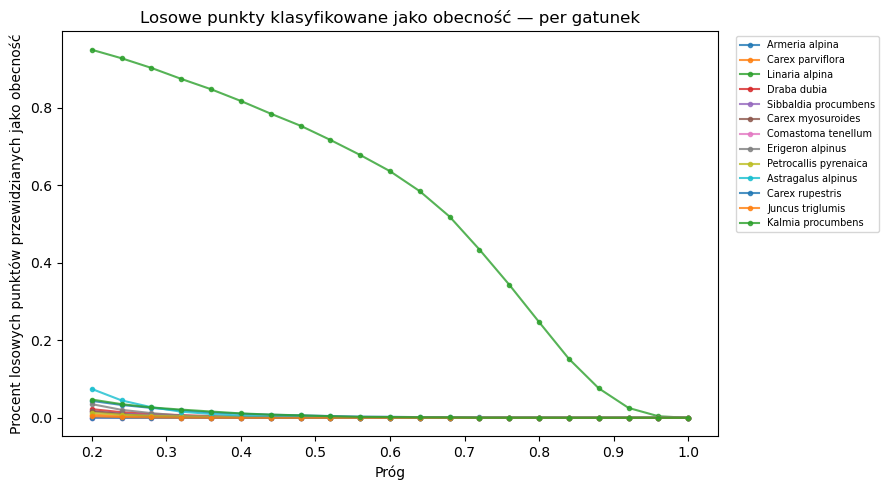

In [44]:
# Sprawdźmy ile punktów z pseudo-absencji zostało zaklasyfikowanych jako obecności dla każdego gatunku.
# To może dać nam wyobrażenie o tym, jak model radzi sobie z losowymi punktami.
def random_presence_fraction(rand_proba, thresholds):
    """Procent losowych punktów > próg dla każdego gatunku osobno."""
    P = np.column_stack([
        p[:, 1]
        for p in rand_proba
    ])
    return np.array([(P > thr).mean(axis=0) for thr in thresholds])

thresholds = np.linspace(0.2, 1, 21)
results = random_presence_fraction(rand_proba, thresholds)  # (n_thr, n_species)

fig, ax = plt.subplots(figsize=(9, 5))
for i, sp in enumerate(species_names):
    ax.plot(thresholds, results[:, i], marker='.', label=sp, alpha=0.8)

ax.set_xlabel('Próg')
ax.set_ylabel('Procent losowych punktów przewidzianych jako obecność')
ax.set_title('Losowe punkty klasyfikowane jako obecność — per gatunek')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7)
plt.tight_layout()
plt.show()